# Formation prediction and change detection

**Analytical question:** Describe team shape and identify change candidates.

**Stages in this notebook:** Centroid distributions; exploratory line clustering; fixed-template assignment; persistence.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Center one frame

Understand the subtraction before summarizing distributions.

,player,raw_x,centered_x,centered_y
0,287934,5.39,7.288,-2.059
1,51002,-4.41,-2.512,-5.439
2,51043,-7.32,-5.422,25.301
3,51050,8.65,10.548,-6.399
4,560882,-7.43,-5.532,2.631
5,560983,7.44,9.338,-13.759
6,560986,-2.21,-0.312,-11.229
7,795537,-21.18,-19.282,-2.809
8,797298,-9.27,-7.372,12.111
9,965697,11.36,13.258,1.651


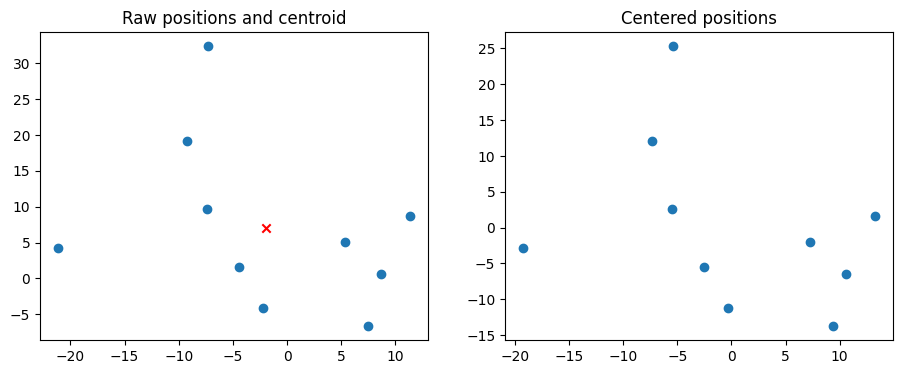

In [4]:
def subtract_centroid(points):
    center=np.asarray(points).mean(axis=0)
    return center,np.asarray(points)-center
one=snapshot[snapshot.team_id.eq(1802)&~snapshot.player_id.isin(keepers)].copy()
center,centered=subtract_centroid(one[['x','y']].to_numpy());display(pd.DataFrame({'player':one.player_id.to_numpy(),'raw_x':one.x.to_numpy(),'centered_x':centered[:,0],'centered_y':centered[:,1]}))
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(one.x,one.y);axs[0].scatter(*center,c='red',marker='x');axs[0].set_title('Raw positions and centroid');axs[1].scatter(centered[:,0],centered[:,1]);axs[1].set_title('Centered positions');plt.show();assert np.allclose(centered.mean(axis=0),0)

## 5. Build player position distributions

Apply the transformation frame by frame, then visualize raw and centered means/covariances on identical samples.

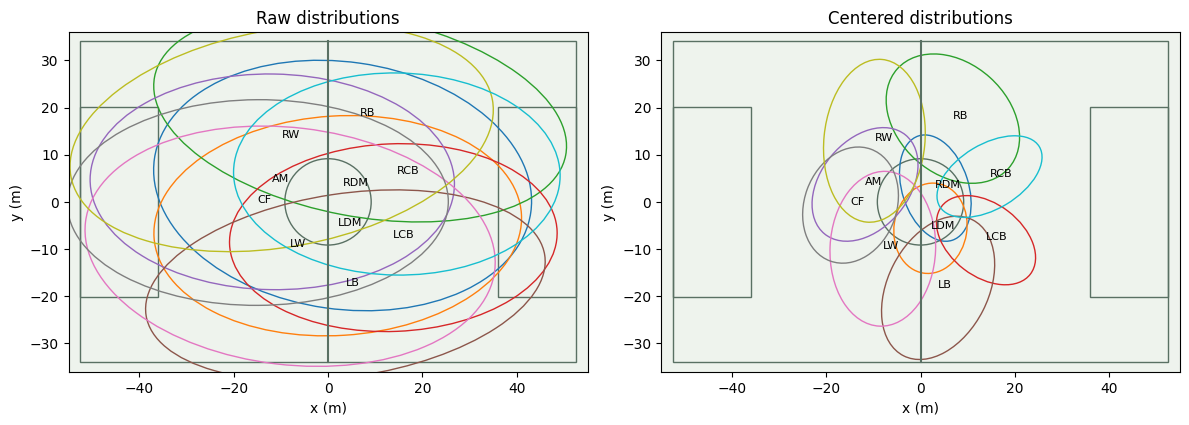

In [5]:
from matplotlib.patches import Ellipse
team=observed[observed.team_id.eq(1802)&~observed.player_id.isin(keepers)].copy()
team[['cx','cy']]=team[['x','y']].to_numpy()-team.groupby(['period_id','frame_id'])[['x','y']].transform('mean').to_numpy()
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,cols,title in zip(axs,[['x','y'],['cx','cy']],['Raw distributions','Centered distributions']):
    pitch(ax);ax.set_title(title)
    for i,(pid,g) in enumerate(team.groupby('player_id')):
        points=g[cols].to_numpy();mean=points.mean(axis=0);vals,vecs=np.linalg.eigh(np.cov(points.T));v=vecs[:,-1]
        ax.add_patch(Ellipse(mean,4*np.sqrt(vals[-1]),4*np.sqrt(vals[0]),angle=np.degrees(np.arctan2(v[1],v[0])),fill=False,color=plt.cm.tab10(i%10)))
        ax.text(*mean,role_labels[pid],fontsize=8)
plt.tight_layout();plt.show()

## 6. Explore longitudinal lines

Clustering helps inspect structure before committing to named formation templates.

,x,y,line
player_id,,,
287934,3.146,3.4380,3
51002,2.145,-5.8020,3
51043,8.083,17.5185,3
51050,14.438,-7.3435,2
560882,-11.833,4.1445,1
560983,4.799,-16.8320,3
560986,-8.318,-11.8075,1
795537,-14.671,-1.5330,1
797298,-10.957,13.2690,1


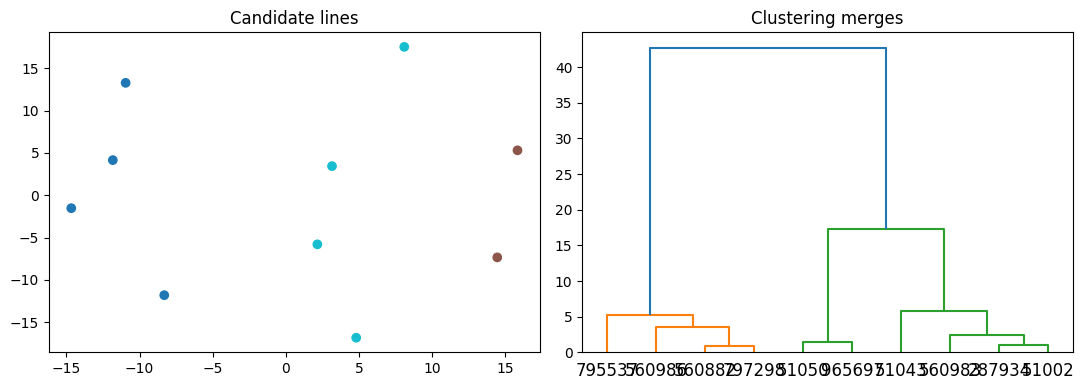

In [6]:
from scipy.cluster.hierarchy import linkage,fcluster,dendrogram
def cluster_lines(points,n_lines=3):
    linkage_matrix=linkage(points[['x']].to_numpy(),method='ward')
    return fcluster(linkage_matrix,n_lines,criterion='maxclust'),linkage_matrix
shape=team.groupby('player_id')[['cx','cy']].median().rename(columns={'cx':'x','cy':'y'})
labels,merges=cluster_lines(shape);display(shape.assign(line=labels))
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(shape.x,shape.y,c=labels,cmap='tab10');axs[0].set_title('Candidate lines');dendrogram(merges,labels=shape.index.tolist(),ax=axs[1]);axs[1].set_title('Clustering merges');plt.tight_layout();plt.show()

## 7. Construct formation templates

Define the model inventory and scale before comparing players with slots.

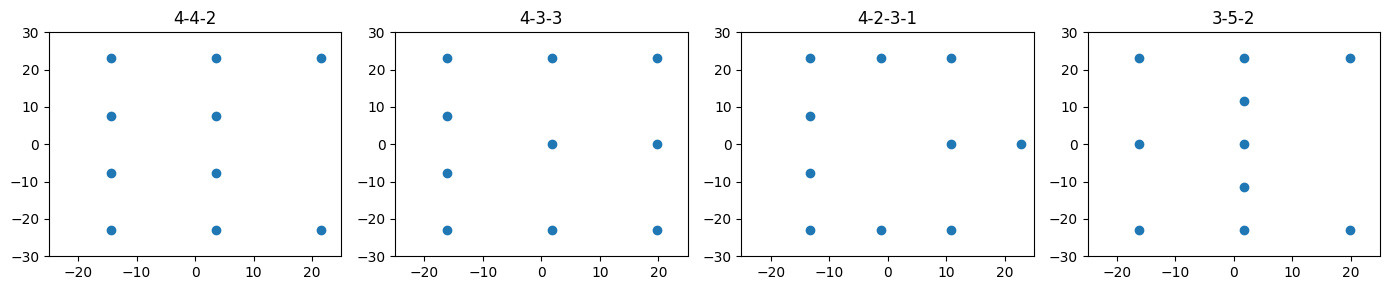

In [7]:
from scipy.optimize import linear_sum_assignment
templates={}
for name,lines in {'4-4-2':[4,4,2],'4-3-3':[4,3,3],'4-2-3-1':[4,2,3,1],'3-5-2':[3,5,2]}.items():
    t=np.array([(x,y) for x,n in zip(np.linspace(-18,18,len(lines)),lines) for y in (np.linspace(-23,23,n) if n>1 else [0])]);templates[name]=t-t.mean(axis=0)
fig,axs=plt.subplots(1,4,figsize=(14,3))
for ax,(name,t) in zip(axs,templates.items()):ax.scatter(t[:,0],t[:,1]);ax.set(title=name,xlim=(-25,25),ylim=(-30,30))
plt.tight_layout();plt.show()

## 8. Inspect one assignment cost matrix

Calculate and inspect pairwise player-slot costs before selecting a formation.

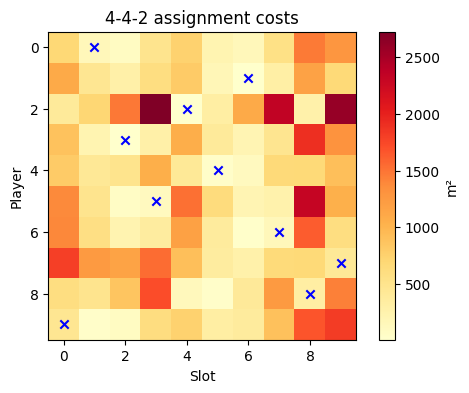

,player_index,slot,residual_m
0,0,1,12.048616
1,1,6,2.479162
2,2,4,2.935010
3,3,2,4.055229
4,4,5,5.393567
5,5,3,10.536599
6,6,7,12.221595
7,7,9,20.323622
8,8,8,17.916649
9,9,0,21.379522


In [8]:
def assignment_costs(points,template):
    centered=points-points.mean(axis=0)
    return ((centered[:,None]-template[None])**2).sum(axis=2)
points=-one[['x','y']].to_numpy();cost=assignment_costs(points,templates['4-4-2']);r,c=linear_sum_assignment(cost)
fig,ax=plt.subplots(figsize=(6,4));im=ax.imshow(cost,cmap='YlOrRd');ax.scatter(c,r,marker='x',c='blue');ax.set(xlabel='Slot',ylabel='Player',title='4-4-2 assignment costs');fig.colorbar(im,ax=ax,label='m²');plt.show()
display(pd.DataFrame({'player_index':r,'slot':c,'residual_m':np.sqrt(cost[r,c])}))

## 9. Compare templates and predict a candidate

Use the inspected cost calculation inside the full scorer.

In [9]:
def score_templates(points):
    fits=[]
    for name,t in templates.items():
        cost=assignment_costs(np.asarray(points),t);r,c=linear_sum_assignment(cost)
        fits.append((name,np.sqrt(cost[r,c].mean()),c))
    return sorted(fits,key=lambda z:z[1])
scores=score_templates(points);display(pd.DataFrame([(name,cost) for name,cost,_ in scores],columns=['candidate','RMS metres']))
assert score_templates(templates['4-3-3'][::-1]+20)[0][1]<1e-10

,candidate,RMS metres
0,4-2-3-1,12.027488
1,4-4-2,12.872421
2,3-5-2,13.140114
3,4-3-3,13.685630


## 10. Score comparable defensive windows

Create the time-series inputs before applying persistence.

In [10]:
team['window']=(team.seconds//30).astype(int);records=[]
for (period,window),g in team[team.team_in_possession.eq(871)].groupby(['period_id','window']):
    per_player=g.groupby('player_id').agg(cx=('cx','median'),cy=('cy','median'),n=('frame_id','size'))
    if len(per_player)!=10 or per_player.n.min()<50:continue
    fits=score_templates(-per_player[['cx','cy']].to_numpy());records.append(dict(period=period,window=window,label=fits[0][0],cost=fits[0][1],margin=fits[1][1]-fits[0][1]))
timeline=pd.DataFrame(records);display(timeline.head(10))

,period,window,label,cost,margin
0,1,1,4-2-3-1,14.533782,1.217760
1,1,4,4-2-3-1,12.106122,1.425694
2,1,5,4-2-3-1,11.858913,0.825284
3,1,7,4-2-3-1,10.126093,1.074907
4,1,8,4-2-3-1,11.115656,1.301365
5,1,9,4-2-3-1,9.273839,1.216594
6,1,12,4-2-3-1,10.309313,0.024867
7,1,16,4-3-3,11.383976,0.049217
8,1,18,4-2-3-1,12.881668,0.539916
9,1,19,4-2-3-1,11.307293,1.123217


## 11. Final output: persistent change candidates

Missing windows reset candidate evidence. Confirmed labels are retained, without claiming that missing intervals prove stability.

,period,label,cost,margin,confirmed
window,,,,,
1,1.0,4-2-3-1,14.533782,1.217760,None
2,NaN,NaN,NaN,NaN,None
3,NaN,NaN,NaN,NaN,None
4,1.0,4-2-3-1,12.106122,1.425694,None
5,1.0,4-2-3-1,11.858913,0.825284,None
6,NaN,NaN,NaN,NaN,None
7,1.0,4-2-3-1,10.126093,1.074907,None
8,1.0,4-2-3-1,11.115656,1.301365,None
9,1.0,4-2-3-1,9.273839,1.216594,4-2-3-1


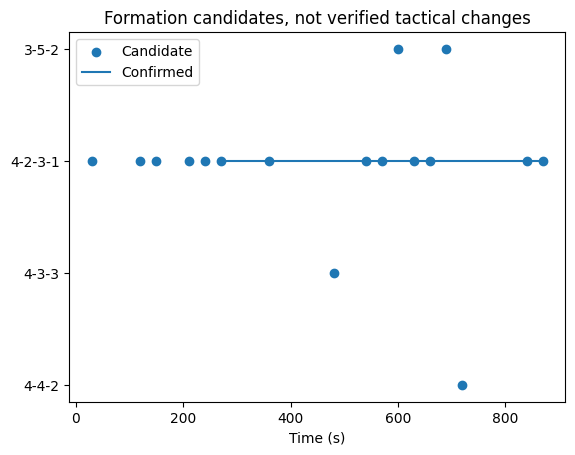

In [11]:
def confirm(sequence,n=3):
    current=None;candidate=None;count=0;result=[]
    for label in sequence:
        if not isinstance(label,str):candidate=None;count=0
        else:
            count=count+1 if label==candidate else 1;candidate=label
            if count>=n:current=candidate
        result.append(current)
    return result
for period,g in timeline.groupby('period'):
    g=g.set_index('window');g=g.reindex(range(int(g.index.min()),int(g.index.max())+1));g['confirmed']=confirm(g.label)
    display(g.head(12));mapping={v:i for i,v in enumerate(templates)}
    plt.scatter(g.index*30,g.label.map(mapping),label='Candidate');plt.plot(g.index*30,g.confirmed.map(mapping),label='Confirmed');plt.yticks(range(4),list(templates));plt.xlabel('Time (s)');plt.title('Formation candidates, not verified tactical changes');plt.legend();plt.show()

## Interpretation and limitations

Metadata roles are not frame-level role truth. Covariance ellipses show dispersion, not confidence intervals. These fixed templates do not reproduce elastic [EFPI](https://arxiv.org/abs/2506.23843). Formation-change labels require video review. [Pleuler](https://github.com/devinpleuler/research/blob/master/frame-by-frame-position.md) proposed change detection without testing it.